# Topological Photonic Crystals III — Coupling a Silicon Strip into a Topological Waveguide

A topological waveguide is only useful if light can be fed into it from ordinary
waveguides. This notebook connects a standard 500 nm silicon strip to the TE (air-hole)
domain walls of notebooks 01–02 — the spin-Hall and the valley-Hall wall — first as in the
literature, then through a topology-optimized transition region.

**How the literature connects them.**

| Source (tier) | Connection | Reported |
|---|---|---|
| He et al., *Nat. Commun.* 10, 872 (2019) (high-impact) | 1.7 µm strip butt-coupled to the end of a bearded valley interface | transmission normalized to a straight strip |
| Chen et al., *Opt. Express* 30, 2517 (2022); Mehrabad et al., *Optica* 7, 1690 (2020) | line-defect coupler: holes next to the interface filled over a length L | ≈ 94 % (2D) / ≈ 31 % (3D), bearded interface |
| Yoshimi et al., arXiv:2311.13965 (2023) (preprint) | same, triangular holes, end face through the hole centres | butt < 10 %, L = 6a > 80 % (3D) |

**Scale.** Placing 1550 nm at the operating frequency gives a0 = 632 nm for the spin-Hall
crystal (edge wave at 0.408 c/a0) and a = 367 nm for the valley-Hall crystal (gap centre
0.2368 c/a), i.e. the same physical lattice (a0 ≈ √3 a). The 500 nm strip is w = 0.79 a0
or 1.36 a; the design's minimum length scale is 100 nm.

**Model:** 2D, TE (Hz, Ex, Ey), silicon εd = 11.7 strip, host and design material, air
cladding and holes. Full models: spin-Hall 10 + 10 rows and 15 clusters of wall
(resolution 32/a0), valley-Hall 17 + 17 rows and 25 cells (24/a), the lattice continuing
into the PML. Fundamental TE strip mode launched as a broadband pulse; the power reaching
the wall ("edge channel": within ±1.6 µm of the wall, 13–23 lattice constants
downstream), reflection into the strip mode, everything returning through the input plane
(including scattering into the air at the crystal face) and the power leaving through the
bulk crystals are normalized to the incident mode power.

**Kernel:** `mp` conda env, run from `topological/notebooks/`. FDTD runs:
`scripts/run_coupling.py` (cached in `data/coupling/`); optimizations:
`scripts/topopt_transition.py` (results cached in `data/topopt/`). **Do not use "Run All."**

## 0. Setup

In [1]:
# Imports, style, cached runs, frequency bands.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import yaml
from matplotlib.colors import LogNorm
from matplotlib.patches import Polygon

from pic_toolkit import style
from pic_toolkit.meep_sim import topological_pc as tp

style.apply_style()
DATA = Path.cwd().parent / "data"
CPL, TOP = DATA / "coupling", DATA / "topopt"
run = lambda name: dict(np.load(CPL / f"{name}.npz"))
# shared bulk gap of each wall at the FDTD resolution, and the optimization bands
GAP = {"spin": (0.4020, 0.4131), "valley": (0.2280, 0.2455)}
BAND = {"spin": (0.4045, 0.4075), "valley": (0.232, 0.2415)}
UNIT = {"spin": "a0", "valley": "a"}
nm = lambda f, scale: f"{(BAND[scale][1] - BAND[scale][0]) / np.mean(BAND[scale]) * 1550:.0f} nm"
print(f"a0 = {tp.A0_NM:.0f} nm, a = {tp.A_NM:.0f} nm; strip w = {tp.strip_width('spin_te'):.3f} a0 = "
      f"{tp.strip_width('valley_te'):.3f} a; optimization bands ≈ {nm(0, 'spin')} (spin), {nm(0, 'valley')} (valley)")

a0 = 632 nm, a = 367 nm; strip w = 0.791 a0 = 1.362 a; optimization bands ≈ 11 nm (spin), 62 nm (valley)


## 1. The input strip

A straight 500 nm strip (w = 0.79 a0), fundamental TE mode over the band: transmission over
16.5 a0, the share of the launched flux in the fundamental mode, and its effective index
against the analytic slab solution. In this bulk-index 2D model the strip also guides
higher-order modes (a 220 nm slab would lower the index and make it single-mode); only the
fundamental mode is launched.

transmission (mode) over 16.5 a0: 0.99998-1.00002; fundamental share of launched flux ≥ 0.99973
n_eff vs analytic: max relative difference 0.27%; guided modes at 0.408 c/a0: [('even', 3.071), ('odd', 1.763), ('even', 1.001)]


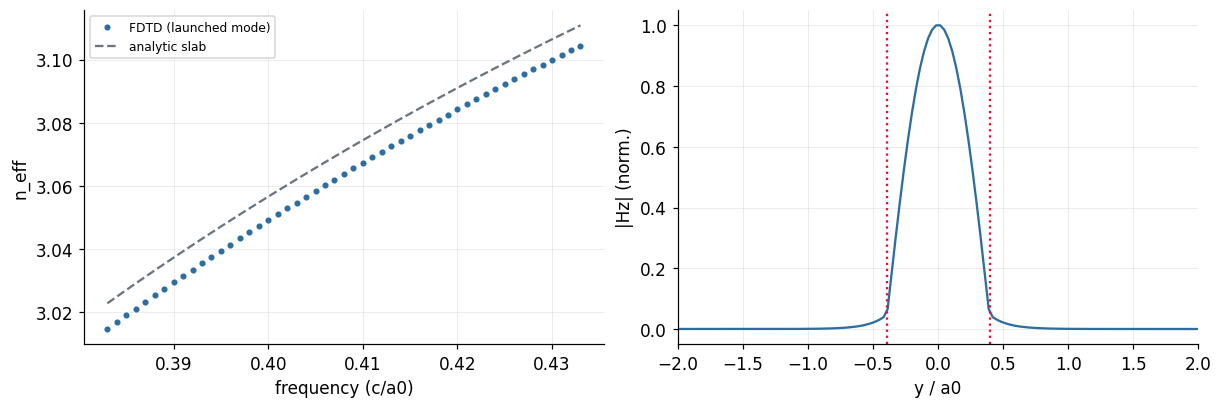

In [2]:
# Straight-strip check.
sw = run("strip")
f = sw["freqs"]
n_an = np.array([tp.slab_modes(float(sw["w"]), fi)[0][1] for fi in f])
print(f"transmission (mode) over {float(sw['length']):.1f} a0: {np.min(sw['mode_out'] / sw['mode_in']):.5f}-"
      f"{np.max(sw['mode_out'] / sw['mode_in']):.5f}; fundamental share of launched flux ≥ {np.min(sw['mode_in'] / sw['flux_in']):.5f}")
print(f"n_eff vs analytic: max relative difference {np.max(np.abs(sw['neff'] / n_an - 1)):.2%}; "
      f"guided modes at 0.408 c/a0: {[(p, round(n, 3)) for p, n in tp.slab_modes(float(sw['w']), 0.408)]}")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained")
axes[0].plot(f, sw["neff"], ".", color=style.COLOR_STEEL, label="FDTD (launched mode)")
axes[0].plot(f, n_an, color=style.COLOR_REFERENCE, ls="--", label="analytic slab")
axes[0].set_xlabel("frequency (c/a0)"); axes[0].set_ylabel("n_eff"); axes[0].legend(fontsize=8)
hz = sw["hz_profile"]
axes[1].plot(sw["y"], np.abs(hz) / np.abs(hz).max(), color=style.COLOR_STEEL)
for s in (-1, 1):
    axes[1].axvline(s * float(sw["w"]) / 2, color=style.COLOR_ANNOTATION, ls=":")
axes[1].set_xlim(-2, 2); axes[1].set_xlabel("y / a0"); axes[1].set_ylabel("|Hz| (norm.)")
plt.show()

## 2. Literature-style connections

Butt coupling of the strip to both walls (the end face of the valley crystal crosses the
centres of a row of holes, as in Yoshimi et al.), and for the valley wall the line-defect
coupler (L = 6) and, as a reference, the strip's first **odd** mode as input.

The valley result needs a symmetry argument. The bearded valley wall is mirror-symmetric
about the wall line and its edge mode is odd (notebook 01), while the fundamental strip
mode is even. Any junction that keeps the mirror symmetry — butt coupling of any strip
width, the line defect — therefore couples *nothing* into the wall; the odd strip mode
does couple. (Yoshimi et al. describe their bearded interface as glide- rather than
mirror-symmetric, which has no such rule.) The spin-Hall wall joins two different
crystals, has no mirror symmetry, and butt coupling works weakly.

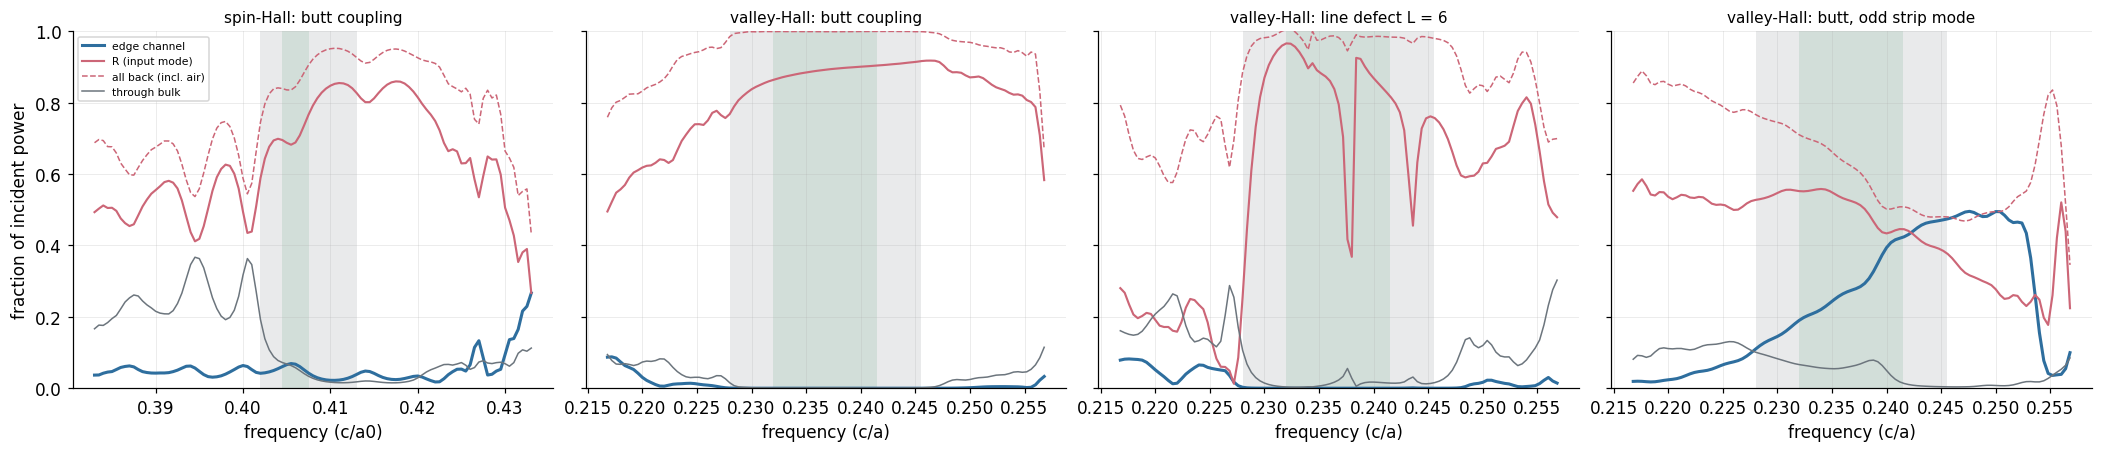

                        connection  edge ch. (band)  gap avg   peak      R   bulk  balance
          spin-Hall: butt coupling           0.0594   0.0415  0.069  0.712  0.052   0.0007
        valley-Hall: butt coupling           0.0000   0.0000  0.000  0.889  0.001   0.0015
    valley-Hall: line defect L = 6           0.0000   0.0002  0.003  0.842  0.014   0.0476
 valley-Hall: butt, odd strip mode           0.2862   0.2919  0.472  0.510  0.058   0.0012


In [3]:
# Spectra of the literature-style connections.
def budget_plot(ax, o, scale, title, opt=False):
    f = o["freqs"]
    ax.axvspan(*GAP[scale], color=style.COLOR_REFERENCE, alpha=0.15, lw=0)
    ax.axvspan(*BAND[scale], color=style.COLOR_SEAGREEN, alpha=0.12, lw=0)
    ax.plot(f, o["T_wall"], color=style.COLOR_SEAGREEN if opt else style.COLOR_STEEL, lw=2, label="edge channel")
    ax.plot(f, o["R"], color=style.COLOR_ROSE, lw=1.4, label="R (input mode)")
    ax.plot(f, o["back"], color=style.COLOR_ROSE, lw=1, ls="--", label="all back (incl. air)")
    ax.plot(f, o["top"] + o["bottom"], color=style.COLOR_REFERENCE, lw=1, label="through bulk")
    ax.set_title(title, fontsize=10); ax.set_xlabel(f"frequency (c/{UNIT[scale]})"); ax.set_ylim(0, 1)

lit = [("spin", "spin_butt", "spin-Hall: butt coupling"), ("valley", "valley_butt", "valley-Hall: butt coupling"),
       ("valley", "valley_ld6", "valley-Hall: line defect L = 6"), ("valley", "valley_odd", "valley-Hall: butt, odd strip mode")]
fig, axes = plt.subplots(1, 4, figsize=(19, 4), sharey=True, layout="constrained")
for ax, (sc, name, t) in zip(axes, lit):
    budget_plot(ax, run(name), sc, t)
axes[0].set_ylabel("fraction of incident power"); axes[0].legend(fontsize=7)
fig.savefig(DATA / "fig_coupling_literature.png", dpi=150, bbox_inches="tight")
plt.show()

def summary(o, scale):
    f = o["freqs"]; mb = (f >= BAND[scale][0]) & (f <= BAND[scale][1]); mg = (f >= GAP[scale][0]) & (f <= GAP[scale][1])
    return {"band": o["T_wall"][mb].mean(), "gap": o["T_wall"][mg].mean(), "peak": o["T_wall"][mg].max(),
            "R": o["R"][mb].mean(), "bulk": (o["top"] + o["bottom"])[mb].mean(),
            "balance": np.abs(o["T_all"] + o["back"] + o["top"] + o["bottom"] - 1)[mg].max()}
print(f"{'connection':>34} {'edge ch. (band)':>16} {'gap avg':>8} {'peak':>6} {'R':>6} {'bulk':>6} {'balance':>8}")
for sc, name, t in lit:
    s = summary(run(name), sc)
    print(f"{t:>34} {s['band']:>16.4f} {s['gap']:>8.4f} {s['peak']:>6.3f} {s['R']:>6.3f} {s['bulk']:>6.3f} {s['balance']:>8.4f}")

`balance` is the largest deviation of the total outgoing flux from the incident flux
inside the gap. The filled line-defect section is a short cavity with sharp resonances
(the reflection dips near 0.238 c/a); their slow ring-down limits the balance there to
≈ 5 % around 0.234 c/a, against < 0.5 % for the other runs. The edge-channel power of
the line defect stays below 0.3 % at every frequency, so this does not affect its
conclusion.

## 3. Topology optimization of the transition

A design region directly after the strip end replaces the crystal there: 4 × 4 lattice
constants (x ∈ [0, 4], y ∈ [−2, 2]), i.e. four clusters / cells along the wall and about
4.6 rows across (2.5 µm square for spin-Hall, 1.5 µm for valley-Hall). The material
varies between air and silicon on a 97 × 97 grid. The objective is the mean edge-channel
power over the band (5 frequencies for valley-Hall, ≈ 62 nm; 3 for spin-Hall, ≈ 11 nm on
the lower edge branch, below the edge-band crossing), with gradients from Meep's adjoint
solver, nlopt MMA, a conic filter for a 100 nm length scale, and a projection driven to a
binary structure:

| | spin-Hall | valley-Hall |
|---|---|---|
| reduced model | 6 + 6 rows, resolution 24/a0 | 10 + 10 rows, resolution 24/a |
| start | uniform gray | gray + small random asymmetric noise (the design must break the wall's mirror symmetry) |
| binarization | tanh projection β 8 → 64, then smoothed projection (Hammond et al.) β 128 → 256 → ∞ | MaterialGrid with subpixel averaging, β 8 → 16 → 32 → 64 → ∞ |
| DFT convergence | decay 10⁻⁵ | decay 10⁻⁹ (accurate adjoint gradients) |

The final design is the 0.5 level set of the filtered field. Every design is validated in
the full model as that binary structure with subpixel smoothing.

> **STOP -- each optimization takes several hours** (`scripts/topopt_transition.py`). The
> histories and designs are read from `data/topopt/`.

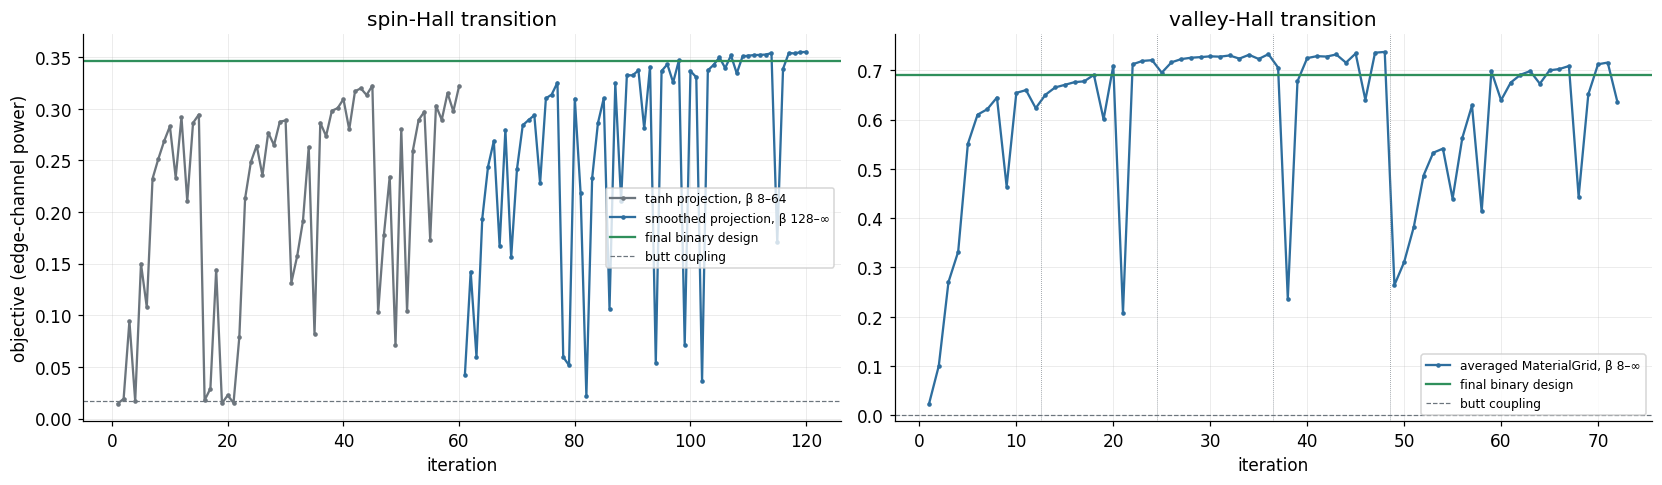

spin-Hall:   butt 0.0171 -> final binary 0.3466 (reduced model)
valley-Hall: butt 0.00003 -> final binary 0.6905 (reduced model)


In [4]:
# Optimization histories (reduced models).
s1, s2 = np.load(TOP / "spin_stage1_history.npz"), np.load(TOP / "spin_stage2_history.npz")
vh = np.load(TOP / "valley_history.npz")
ds, dv = np.load(TOP / "spin_design.npz"), np.load(TOP / "valley_design.npz")
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3), layout="constrained")
n1 = len(s1["J"])
axes[0].plot(np.arange(1, n1 + 1), s1["J"], ".-", color=style.COLOR_REFERENCE, ms=4, label="tanh projection, β 8–64")
axes[0].plot(np.arange(n1 + 1, n1 + len(s2["J"]) + 1), s2["J"], ".-", color=style.COLOR_STEEL, ms=4,
             label="smoothed projection, β 128–∞")
axes[0].axhline(float(ds["j_final"]), color=style.COLOR_SEAGREEN, label="final binary design")
axes[0].axhline(float(s1["j_crystal"]), color=style.COLOR_REFERENCE, ls="--", lw=0.8, label="butt coupling")
axes[0].set_title("spin-Hall transition"); axes[0].set_xlabel("iteration"); axes[0].set_ylabel("objective (edge-channel power)")
axes[0].legend(fontsize=8)
it = np.arange(1, len(vh["J"]) + 1)
axes[1].plot(it, vh["J"], ".-", color=style.COLOR_STEEL, ms=4, label="averaged MaterialGrid, β 8–∞")
for b in np.unique(vh["beta"])[1:]:
    axes[1].axvline(np.argmax(vh["beta"] == b) + 0.5, color=style.COLOR_REFERENCE, lw=0.5, ls=":")
axes[1].axhline(float(dv["j_final"]), color=style.COLOR_SEAGREEN, label="final binary design")
axes[1].axhline(float(vh["j_crystal"]), color=style.COLOR_REFERENCE, ls="--", lw=0.8, label="butt coupling")
axes[1].set_title("valley-Hall transition"); axes[1].set_xlabel("iteration"); axes[1].legend(fontsize=8)
fig.savefig(DATA / "fig_topopt_history.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"spin-Hall:   butt {float(s1['j_crystal']):.4f} -> final binary {float(ds['j_final']):.4f} (reduced model)")
print(f"valley-Hall: butt {float(vh['j_crystal']):.5f} -> final binary {float(dv['j_final']):.4f} (reduced model)")

## 4. Final structures

Permittivity of the junction in the full model before (crystal butt-coupled to the strip)
and after optimization, with the replaced crystal outlined on the optimized design. Below:
the binary design grids and a fabrication check — the share of pixels changed by a
morphological opening and closing with a 100 nm disk (0 = no feature below 100 nm).

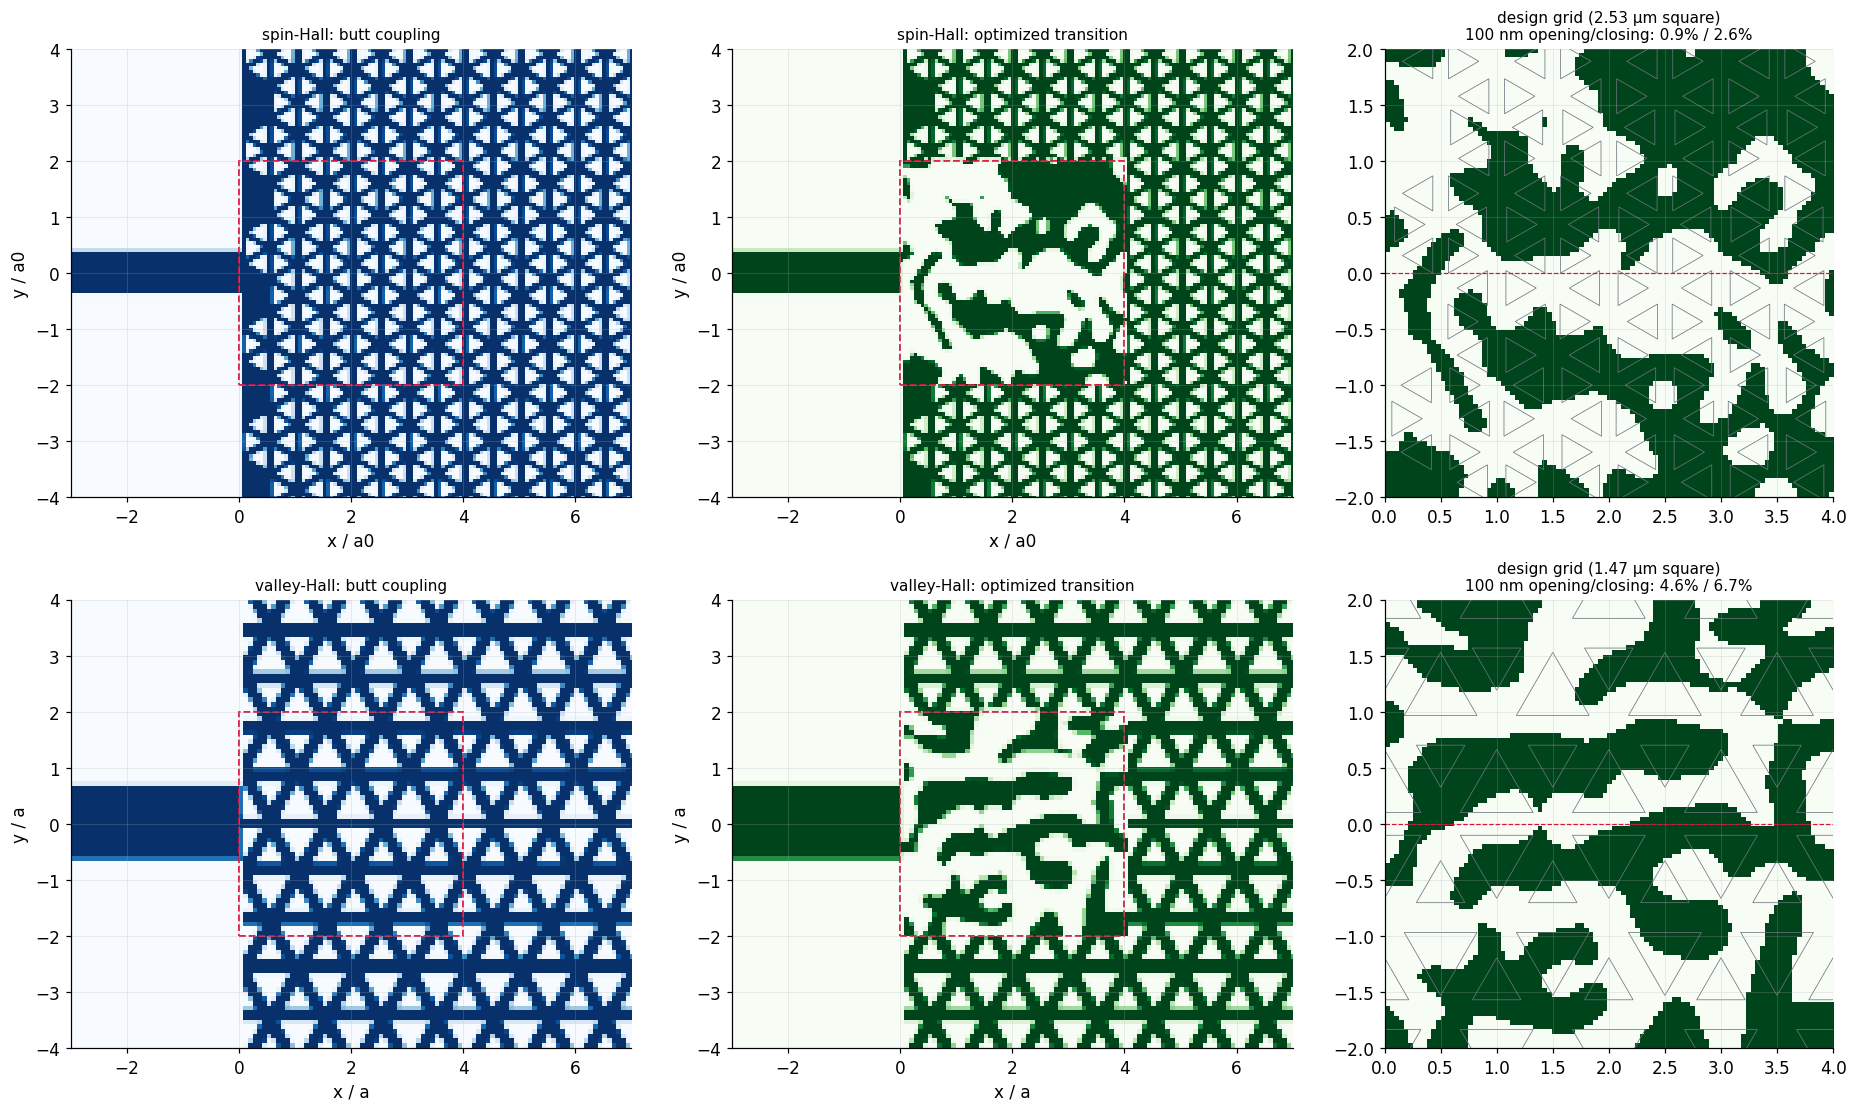

In [5]:
# Permittivity maps: butt coupling (Blues) vs optimized (Greens), and the design grids.
from scipy import ndimage
cases = {"spin": ("spin_butt", "spin_topopt", ds), "valley": ("valley_butt", "valley_topopt", dv)}
fig, axes = plt.subplots(2, 3, figsize=(17, 10), width_ratios=[1, 1, 0.85], layout="constrained")
for r, (sc, (b, t, d)) in enumerate(cases.items()):
    for c, (name, cmap) in enumerate(((b, style.CMAP_PERMITTIVITY_BASELINE), (t, style.CMAP_PERMITTIVITY_OPTIMIZED))):
        o = run(name); ex = o["extent"]
        ax = axes[r, c]
        ax.imshow(o["eps"].T, origin="lower", extent=ex, cmap=cmap, vmin=1, vmax=tp.EPS_D, interpolation="nearest")
        ax.add_patch(plt.Rectangle((0, -2), 4, 4, fill=False, ec=style.COLOR_ANNOTATION, lw=1.2, ls="--"))
        ax.set_xlim(-3, 7); ax.set_ylim(-4, 4); ax.set_aspect("equal")
        ax.set_title(f"{sc}-Hall: {'butt coupling' if c == 0 else 'optimized transition'}", fontsize=10)
        ax.set_xlabel(f"x / {UNIT[sc]}"); ax.set_ylabel(f"y / {UNIT[sc]}")
    ax = axes[r, 2]
    ax.imshow(d["weights"].T, origin="lower", extent=[0, 4, -2, 2], cmap=style.CMAP_PERMITTIVITY_OPTIMIZED, vmin=0, vmax=1)
    kind = f"{sc}_te"
    for sh in tp.wall_shapes(kind, -1, 6, 4, 0.0 if sc == "spin" else -0.5, x_face=0.0):
        ax.add_patch(Polygon(sh["poly"], fill=False, ec=style.COLOR_REFERENCE, lw=0.5))
    ax.axhline(0, color=style.COLOR_ANNOTATION, lw=0.8, ls="--")
    ax.set_xlim(0, 4); ax.set_ylim(-2, 2); ax.set_aspect("equal")
    w = d["weights"].astype(bool); r_px = 0.5 * float(d["min_len"]) * float(d["res"])
    yy, xx = np.mgrid[-3:4, -3:4]; disk = xx ** 2 + yy ** 2 <= r_px ** 2
    op, cl = (ndimage.binary_opening(w, disk) != w).mean(), (ndimage.binary_closing(w, disk) != w).mean()
    size_um = 4 * (tp.A0_NM if sc == "spin" else tp.A_NM) / 1000
    ax.set_title(f"design grid ({size_um:.2f} µm square)\n100 nm opening/closing: {op:.1%} / {cl:.1%}", fontsize=10)
fig.savefig(DATA / "fig_topopt_structures.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Before and after

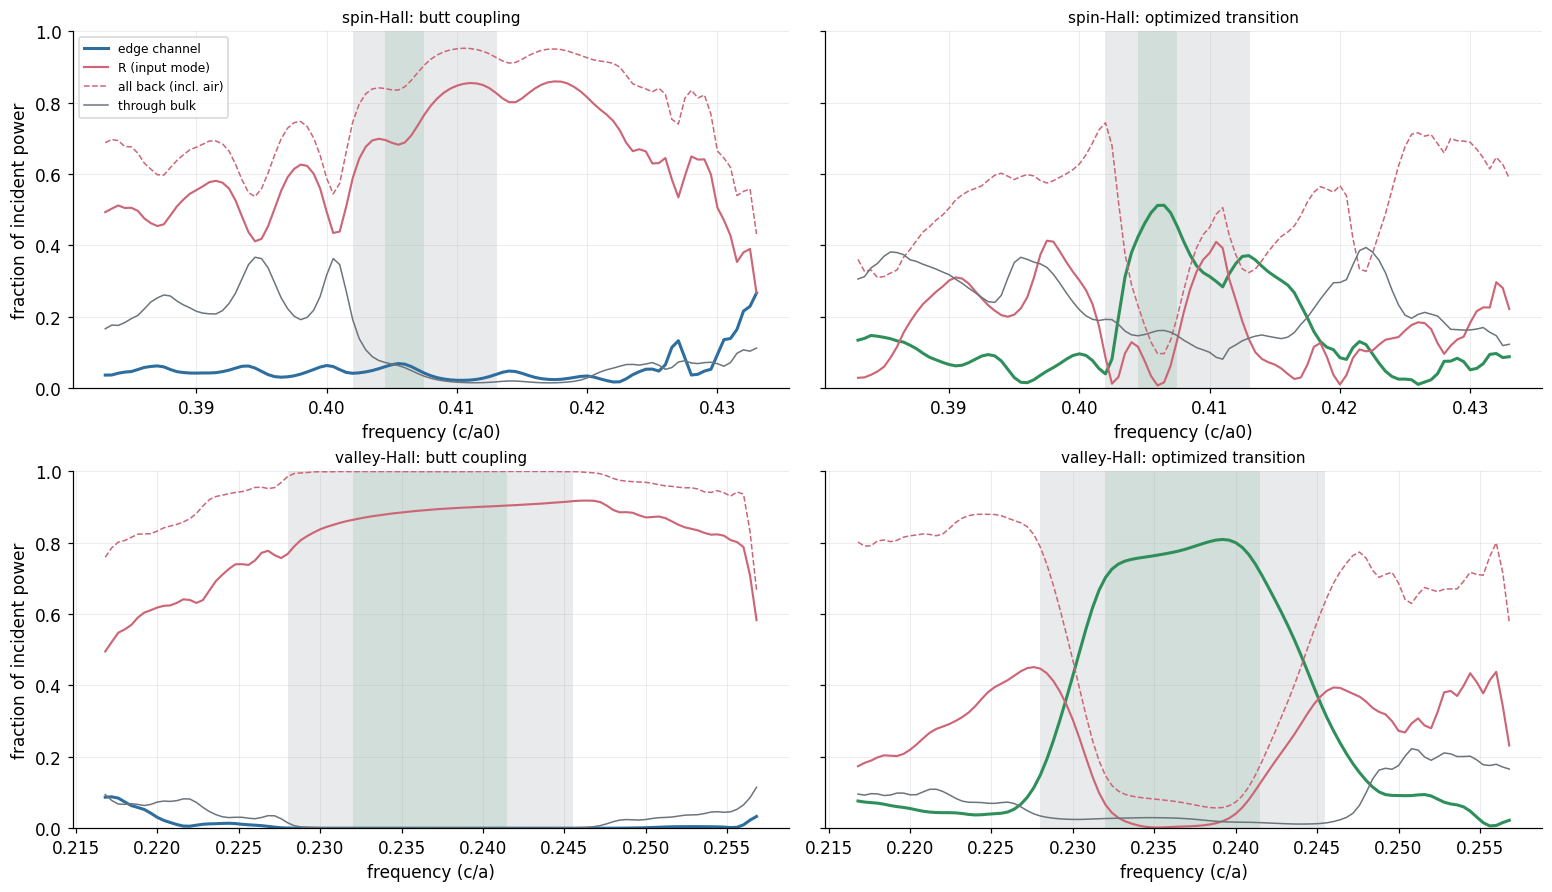

                                edge ch. (band)  gap avg   peak      R   bulk  balance
      spin-Hall, butt coupling            0.059    0.042  0.069  0.712  0.052   0.0007
          spin-Hall, optimized            0.487    0.367  0.513  0.055  0.156   0.0037
    valley-Hall, butt coupling            0.000    0.000  0.000  0.889  0.001   0.0015
        valley-Hall, optimized            0.771    0.635  0.809  0.024  0.024   0.0009
(spin-Hall transition optimized with the valley-Hall procedure: 0.380 over the same band)


In [6]:
# Power budget spectra, butt coupling vs optimized, both walls.
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=True, layout="constrained")
for r, (sc, (b, t, d)) in enumerate(cases.items()):
    budget_plot(axes[r, 0], run(b), sc, f"{sc}-Hall: butt coupling")
    budget_plot(axes[r, 1], run(t), sc, f"{sc}-Hall: optimized transition", opt=True)
    axes[r, 0].set_ylabel("fraction of incident power")
axes[0, 0].legend(fontsize=8)
fig.savefig(DATA / "fig_topopt_spectra.png", dpi=150, bbox_inches="tight")
plt.show()

results = {}
print(f"{'':>30} {'edge ch. (band)':>16} {'gap avg':>8} {'peak':>6} {'R':>6} {'bulk':>6} {'balance':>8}")
for sc, (b, t, d) in cases.items():
    for lab, name in (("butt coupling", b), ("optimized", t)):
        s = summary(run(name), sc); results[(sc, lab)] = s
        print(f"{sc + '-Hall, ' + lab:>30} {s['band']:>16.3f} {s['gap']:>8.3f} {s['peak']:>6.3f} {s['R']:>6.3f} "
              f"{s['bulk']:>6.3f} {s['balance']:>8.4f}")
vp = summary(run("spin_topopt_vp"), "spin") if (CPL / "spin_topopt_vp.npz").exists() else None
if vp:
    print(f"(spin-Hall transition optimized with the valley-Hall procedure: {vp['band']:.3f} over the same band)")

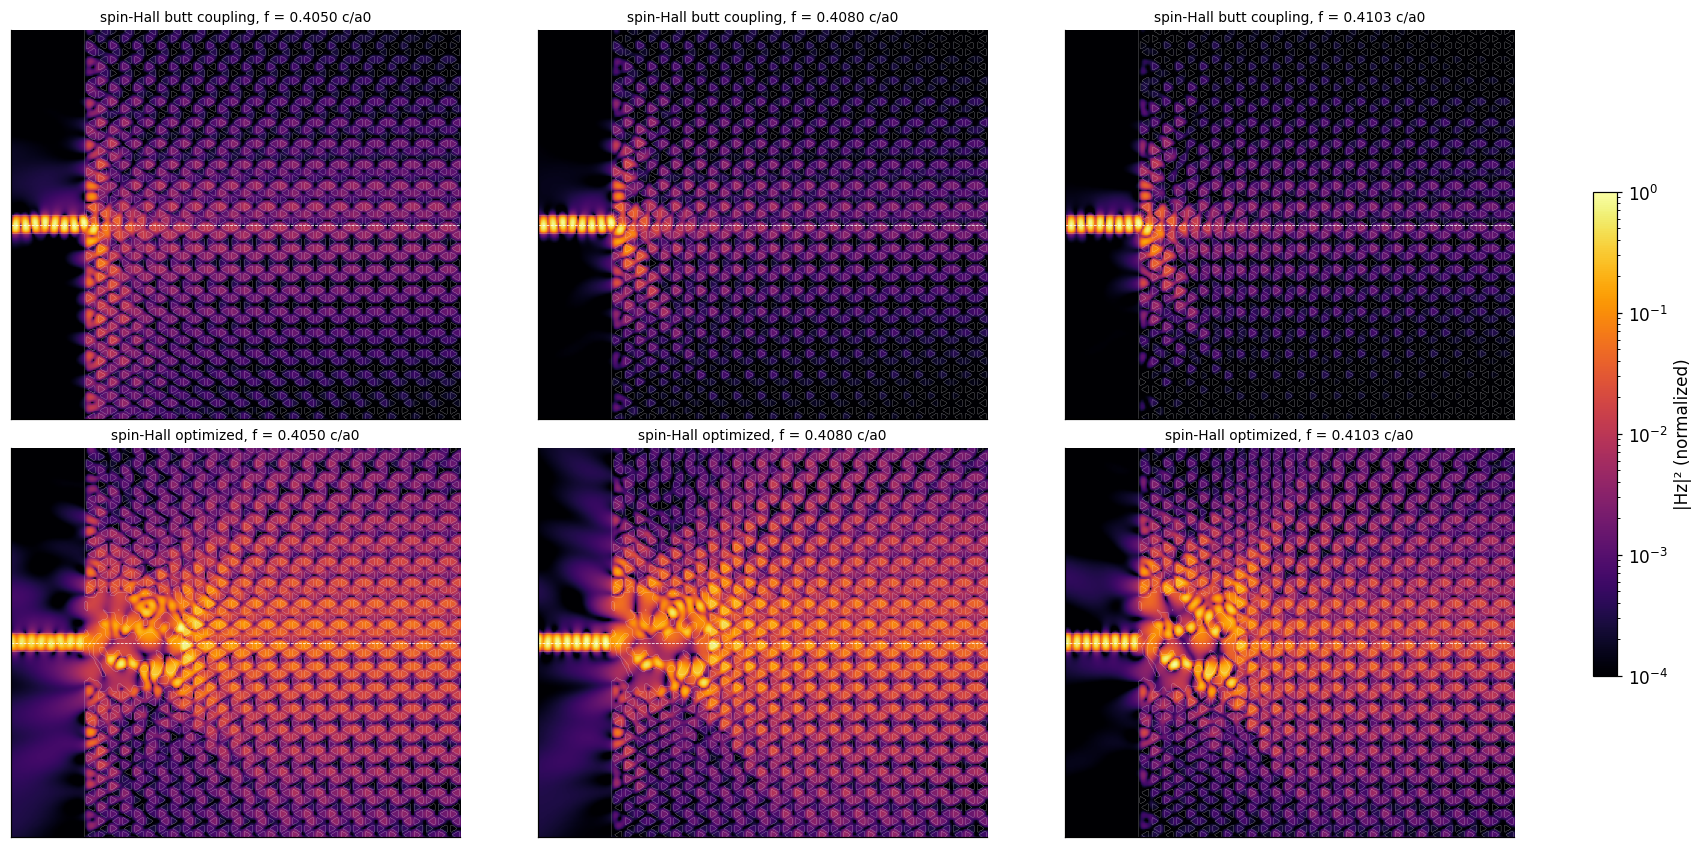

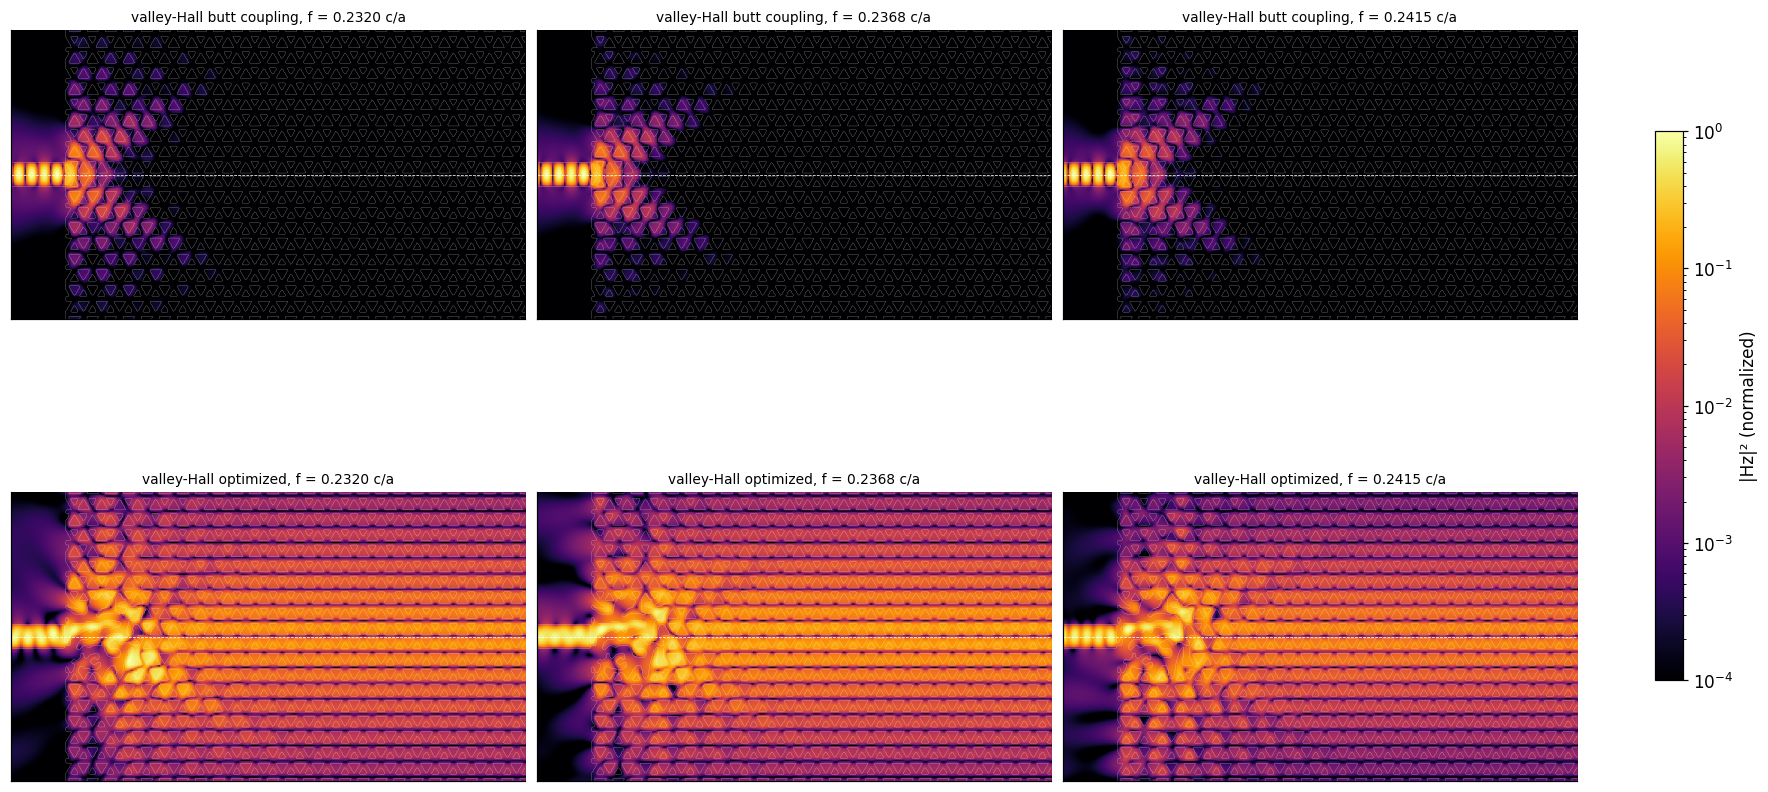

In [7]:
# |Hz|^2 before / after at three frequencies in the band (log scale, normalized per panel).
for sc, (b, t, d) in cases.items():
    fig, axes = plt.subplots(2, 3, figsize=(16, 7.6 if sc == "spin" else 8.4), layout="constrained")
    for r, (lab, name) in enumerate((("butt coupling", b), ("optimized", t))):
        o = run(name); ex = o["extent"]; nx, ny = o["eps"].shape
        x = np.linspace(ex[0], ex[1], nx); y = np.linspace(ex[2], ex[3], ny)
        for c, ff in enumerate(o["field_freqs"]):
            u = np.abs(o["hz"][c]) ** 2
            ax = axes[r, c]
            im = ax.imshow((u / u.max()).T, origin="lower", extent=ex, norm=LogNorm(1e-4, 1), cmap="inferno")
            ax.contour(x, y, o["eps"].T, levels=[6], colors="w", linewidths=0.12)
            ax.axhline(0, color="w", lw=0.5, ls="--")
            ax.set_xlim(-3, ex[1]); ax.set_ylim(-8, 8)
            ax.set_title(f"{sc}-Hall {lab}, f = {ff:.4f} c/{UNIT[sc]}", fontsize=9)
            ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=axes, shrink=0.6, label="|Hz|² (normalized)")
    fig.savefig(DATA / f"fig_topopt_fields_{sc}.png", dpi=120, bbox_inches="tight")
    plt.show()

## 6. Design points

> **STOP -- this writes `data/topopt_{spin,valley}_transition.yaml`.**

Each design point records the geometry (design grid file, region, lattice scale, strip
width), the optimization settings and the full-model performance.

In [8]:
# Save the two transitions as design points.
for sc, (b, t, d) in cases.items():
    o = run(t); s, s0 = results[(sc, "optimized")], results[(sc, "butt coupling")]
    a_nm = tp.A0_NM if sc == "spin" else tp.A_NM
    dp = {"component": f"topological_transition_{sc}_hall_te",
          "parameters": {"crystal": f"{sc}_te", "lattice_constant_nm": float(a_nm),
                         "strip_width_nm": tp.W_STRIP_NM, "design_region_lattice_units": {"center": list(map(float, d["center"])),
                                                                                         "size": list(map(float, d["size"]))},
                         "design_grid_file": f"data/topopt/{sc}_design.npz", "min_length_nm": 100.0,
                         "material": "Si eps 11.7 / air, 2D TE"},
          "measured": {"band_c_per_unit": list(BAND[sc]), "edge_channel_band_mean": float(s["band"]),
                       "edge_channel_gap_mean": float(s["gap"]), "edge_channel_peak": float(s["peak"]),
                       "reflection_band_mean": float(s["R"]), "bulk_loss_band_mean": float(s["bulk"]),
                       "butt_coupling_band_mean": float(s0["band"]),
                       "spectrum": {"freqs": o["freqs"].tolist(), "T_wall": o["T_wall"].tolist(), "R": o["R"].tolist(),
                                    "r_complex_re": np.real(o["r_coef"]).tolist(), "r_complex_im": np.imag(o["r_coef"]).tolist()}}}
    (DATA / f"topopt_{sc}_transition.yaml").write_text(yaml.safe_dump(dp, sort_keys=False))
    print("wrote", f"topopt_{sc}_transition.yaml")

wrote topopt_spin_transition.yaml
wrote topopt_valley_transition.yaml


## 7. Summary

- **Input strip.** The 500 nm silicon strip (0.79 a0 for spin-Hall, 1.36 a for
  valley-Hall) carries its fundamental TE mode without loss (T = 1.000) and its effective
  index agrees with the analytic slab value to 0.3 %.
- **Direct connections are poor, for different reasons.** At the spin-Hall wall the strip
  mode and the edge mode are mismatched in field shape and in momentum (the edge band
  crosses at Γ), so a butt joint couples 5.9 % on average and reflects most of the power.
  At the valley-Hall bearded wall the mismatch is a symmetry one: the wall is
  mirror-symmetric and its TE edge mode is odd, so neither the even strip mode nor an
  even-mode line-defect section can feed it. The odd strip mode, used as a reference,
  couples 28.6 %.
- **Topology optimization** of a four-cell square region (100 nm minimum features, binary
  final design checked in the full model at infinite projection sharpness with subpixel
  averaging) gives an edge-channel coupling of **48.7 %** for spin-Hall (≈ 11 nm band,
  reflection 5.5 %, 16 % into the bulk) and **77.1 %** for valley-Hall (≈ 62 nm band,
  peak 80.9 %, reflection 2.4 %, 2.4 % into the bulk). The valley-Hall design breaks the
  mirror symmetry, which is what lets the even strip mode reach the odd edge mode.
- **Why valley-Hall does better.** Its gap is wider (6.8 % against 3.1 %), its edge band
  lies away from Γ, and its wall leaks little into the bulk; the spin-Hall wall loses
  power into the bulk even for a chiral source (notebook 2), and the transition must also
  bridge a momentum mismatch. Rerunning the spin-Hall optimization with the valley-Hall
  procedure gave 38.0 %, below the design shown here.

The optimization schedules, the representation checks and the alternatives that were
tried are recorded in `docs/simulation_settings_record.md`
(section `meep_sim/topological_pc.py`).